In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import seaborn as sns
%matplotlib inline

# Import Data

In [2]:
# !pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
combined_cycle_power_plant = fetch_ucirepo(id=294)

# data (as pandas dataframes)
X = combined_cycle_power_plant.data.features
y = combined_cycle_power_plant.data.targets

# metadata
print(combined_cycle_power_plant.metadata)

# variable information
print(combined_cycle_power_plant.variables)

{'uci_id': 294, 'name': 'Combined Cycle Power Plant', 'repository_url': 'https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant', 'data_url': 'https://archive.ics.uci.edu/static/public/294/data.csv', 'abstract': 'The dataset contains 9568 data points collected from a Combined Cycle Power Plant over 6 years (2006-2011), when the plant was set to work with full load. ', 'area': 'Computer Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 9568, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['PE'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2014, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C5002N', 'creators': ['Pnar Tfekci', 'Heysem Kaya'], 'intro_paper': {'ID': 406, 'type': 'NATIVE', 'title': 'Prediction of full load electrical power output of a base load operated combined cycle power plant using machine learning methods', 'aut

In [3]:
df = pd.DataFrame(combined_cycle_power_plant.data['features'])
df['target'] = combined_cycle_power_plant.data['targets']
df.head(5)

,AT,V,AP,RH,target
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


# Train Test Split

In [4]:
from sklearn.model_selection import train_test_split

X, y = df[df.columns[:-1]], df[df.columns[-1]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

# Scalling

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# correlation matrix

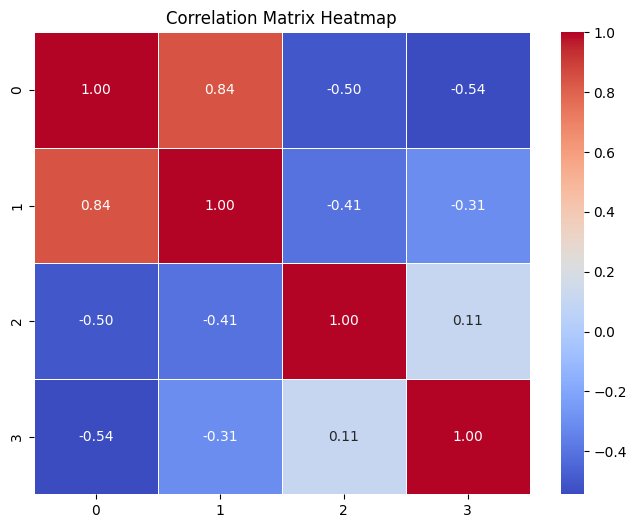

In [6]:
corr_matrix = pd.DataFrame(X_train).corr()
plt.figure(figsize=(8, 6)) # Adjust figure size as needed
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

# SVM training (linear kernal)

In [7]:
import numpy as np
from sklearn.svm import SVR
from itertools import product
from concurrent.futures import ProcessPoolExecutor
from sklearn.metrics import r2_score

def train_and_score_linear(C: float, epsilon: float, X_train: np.ndarray, y_train: np.ndarray, X_val: np.ndarray, y_val: np.ndarray):
    model = SVR(kernel='linear', C=C, epsilon=epsilon)
    model.fit(X=X_train, y=y_train)
    y_pred = model.predict(X=X_val)
    r2 = r2_score(y_true=y_val, y_pred=y_pred)
    return {'C': C, 'epsilon': epsilon}, r2, model


def grid_search_linear(X_train: np.ndarray, y_train: np.ndarray, X_val: np.ndarray, y_val: np.ndarray):
    C_vals = [0.01, 0.1, 1, 10, 100]
    epsilon_vals = [0.001, 0.01, 0.1, 0.5, 1.0]
    param_grid = list(product(C_vals, epsilon_vals))
    
    results = []
    with ProcessPoolExecutor() as executor:
        futures = [
            executor.submit(train_and_score_linear, *params, X_train, y_train, X_val, y_val)
            for params in param_grid
        ]
        
        for f in futures:
            results.append(f.result())
    best_params, best_r2, best_model = max(results, key=lambda x: x[1])
    
    return best_params, best_r2, best_model

In [8]:
linear_best_params, _, linear_best_model = grid_search_linear(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val)
print(f'best fit hyperparms for linear kernal: {linear_best_params}')

best fit hyperparms for linear kernal: {'C': 0.1, 'epsilon': 0.001}


# linear model evaluation

In [9]:
from sklearn.metrics import mean_squared_error

linear_y_test_pred = linear_best_model.predict(X_test)
linear_test_r2 = r2_score(y_true=y_test, y_pred=linear_y_test_pred)
print(f'r2 score: {linear_test_r2}')

linear_test_mse = mean_squared_error(y_true=y_test, y_pred=linear_y_test_pred)
print(f'mse: {linear_test_mse}')

r2 score: 0.9244082467622002
mse: 21.790518539134048


# scatterplot

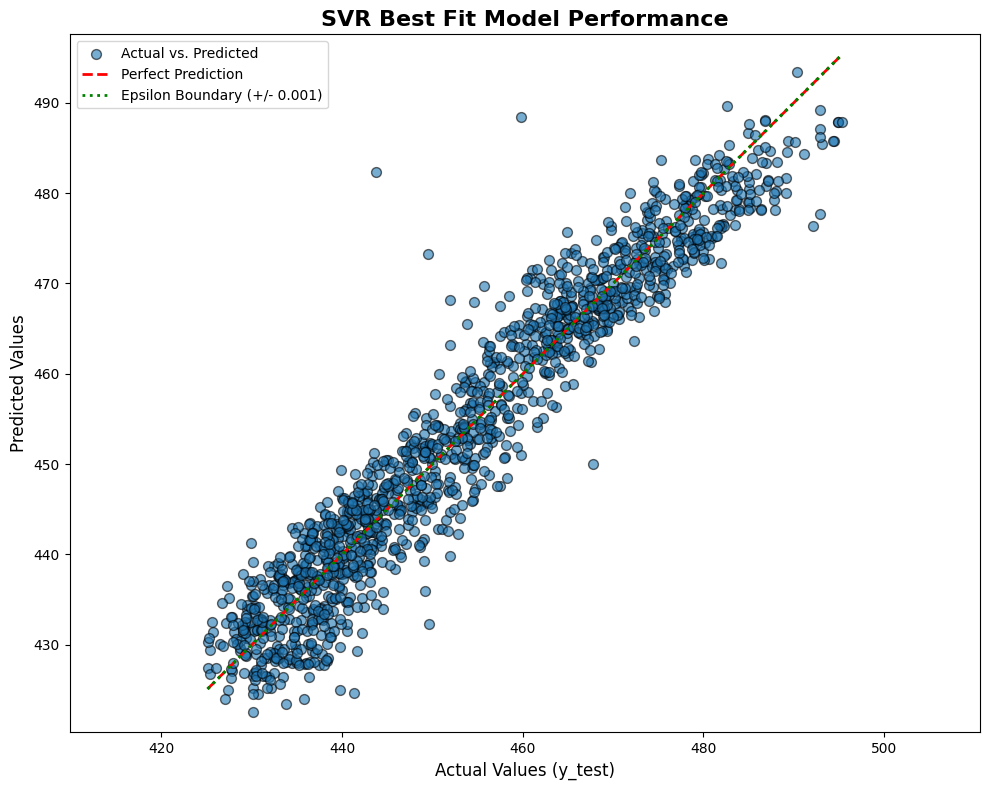

In [10]:
plt.figure(figsize=(10, 8))

plt.scatter(y_test, linear_y_test_pred, alpha=0.6, edgecolors="k", s=50, label="Actual vs. Predicted")

y_test_np = y_test.to_numpy()
sorted_indices = np.argsort(y_test_np)
y_test_sorted = y_test_np[sorted_indices]
y_pred_sorted = linear_y_test_pred[sorted_indices]

plt.plot(y_test_sorted, y_test_sorted, color="red", linestyle="--", linewidth=2, label="Perfect Prediction")

epsilon = linear_best_model.epsilon
plt.plot(y_test_sorted, y_test_sorted + epsilon, color="green", linestyle=":", linewidth=2, label=f"Epsilon Boundary (+/- {epsilon:.3f})")
plt.plot(y_test_sorted, y_test_sorted - epsilon, color="green", linestyle=":", linewidth=2)

plt.title("SVR Best Fit Model Performance", fontsize=16, fontweight="bold")
plt.xlabel("Actual Values (y_test)", fontsize=12)
plt.ylabel("Predicted Values", fontsize=12)
plt.legend(loc="upper left")
plt.axis("equal")
plt.tight_layout()
plt.show()

# RBF kernal SVM regression

In [11]:
def train_and_score_rbf(C, epsilon, gamma, X_train, y_train, X_val, y_val):
    model = SVR(kernel="rbf", gamma=gamma, C=C, epsilon=epsilon)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    r2 = r2_score(y_val, y_pred)
    return (C, epsilon, gamma), r2

def grid_search_rbf(X_train, y_train, X_val, y_val):
    C_vals = [0.1, 1, 10, 100, 1000]
    epsilon_vals = [0.01, 0.1, 0.5, 1.0]
    gamma_vals = [0.001, 0.01, 0.1, 1, 10]
    param_grid = list(product(C_vals, epsilon_vals, gamma_vals))

    results = []
    with ProcessPoolExecutor() as executor:
        futures = [executor.submit(train_and_score_rbf, *params, X_train, y_train, X_val, y_val)
                   for params in param_grid]
        for f in futures:
            results.append(f.result())

    best_params, best_r2 = max(results, key=lambda x: x[1])
    param_dict = {"C": best_params[0], "epsilon": best_params[1], "gamma": best_params[2]}

    best_model = SVR(kernel="rbf", **param_dict)
    best_model.fit(X_train, y_train)

    return param_dict, best_r2, best_model


In [12]:
rbf_best_params, _, rbf_best_model = grid_search_rbf(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val)
print(f'rbf kernel best params: {rbf_best_params}')

rbf kernel best params: {'C': 100, 'epsilon': 1.0, 'gamma': 1}


# Evaluation

In [13]:
rbf_y_pred = rbf_best_model.predict(X_test)
rbf_r2 = r2_score(y_true=y_test, y_pred=rbf_y_pred)
rbf_mse = mean_squared_error(y_true=y_test, y_pred=rbf_y_pred)
print(f'rbf kernal r2 score: {rbf_r2}')
print(f'rbf kernal mse: {rbf_mse}')

rbf kernal r2 score: 0.9459356318435918
rbf kernal mse: 15.584909281210807


# Scatter plot

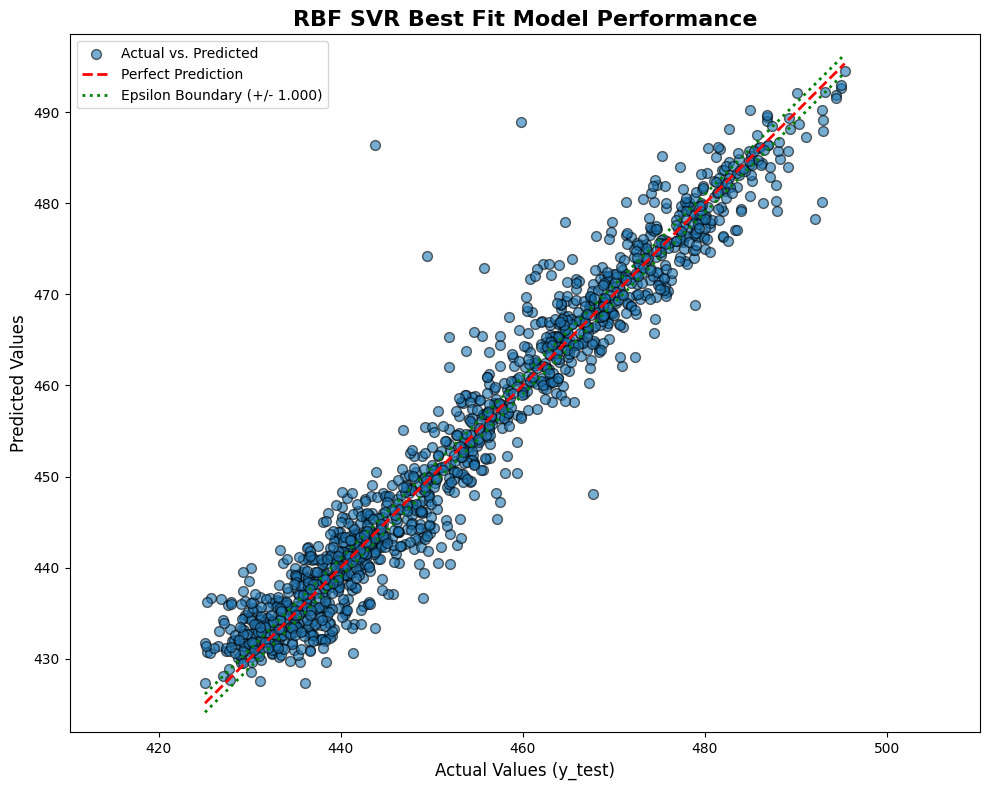

In [14]:
plt.figure(figsize=(10, 8))

plt.scatter(y_test, rbf_y_pred, alpha=0.6, edgecolors="k", s=50, label="Actual vs. Predicted")

y_test_np = np.array(y_test)
sorted_indices = np.argsort(y_test_np)
y_test_sorted = y_test_np[sorted_indices]
y_pred_sorted = rbf_y_pred[sorted_indices]

plt.plot(y_test_sorted, y_test_sorted, color="red", linestyle="--", linewidth=2, label="Perfect Prediction")

epsilon = rbf_best_model.epsilon
plt.plot(y_test_sorted, y_test_sorted + epsilon, color="green", linestyle=":", linewidth=2, label=f"Epsilon Boundary (+/- {epsilon:.3f})")

plt.plot(y_test_sorted, y_test_sorted - epsilon, color="green", linestyle=":", linewidth=2)

plt.title("RBF SVR Best Fit Model Performance", fontsize=16, fontweight="bold")
plt.xlabel("Actual Values (y_test)", fontsize=12)
plt.ylabel("Predicted Values", fontsize=12)
plt.legend(loc="upper left")
plt.axis("equal")
plt.tight_layout()
plt.show()